# Recession Impact Analysis
## Exploratory Data Analysis & Visualizations

Charts show how employment behaved during recessions. Red shaded areas mark official NBER recession periods.

**5 Charts mapped to 5 Hook Questions:**
1. Total nonfarm payroll with recession shading (Macro anchor)
2. White-collar vs blue-collar % crossover (Hook #1)
3. First blood: who drops first around recession start (Hook #2)
4. Vulnerability shift: era-by-era drawdown comparison (Hook #3)
5. Sub-sector bifurcation: individual ticker crashes across recessions (Hook #4)

---


### Step 1: Load tools and data

Reads `master_table.csv` from Notebook 1.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)

df = pd.read_csv(os.path.join( "..", "data", "processed", "master_table.csv"),
                 parse_dates=["date"], index_col="date").sort_index()

print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")
print(f"Columns: {list(df.columns)}")

Loaded 1054 rows x 11 columns
Date range: 1939-01-31 to 2026-10-31
Columns: ['recession_indicator', 'total_nonfarm_payroll', 'construction_employment', 'manufacturing_employment', 'professional_business_services', 'information_sector', 'blue_collar_jobs', 'white_collar_jobs', 'core_cohort_total', 'white_collar_pct', 'blue_collar_pct']


### Step 2: Recession shading helper

Paints background red wherever `recession_indicator` is 1. Used by all charts below.


In [3]:
def shade_recessions(ax, df, col="recession_indicator"):
    in_rec = False
    start = None
    for date, val in df[col].items():
        if val == 1 and not in_rec:
            in_rec = True
            start = date
        elif val == 0 and in_rec:
            in_rec = False
            ax.axvspan(start, date, color="red", alpha=0.25)
    if in_rec:
        ax.axvspan(start, df.index[-1], color="red", alpha=0.25)
    return ax


### Chart 1: Macro anchor â€” Total nonfarm payroll (PAYEMS)

Overall U.S. job market. Red shaded areas mark official recessions.


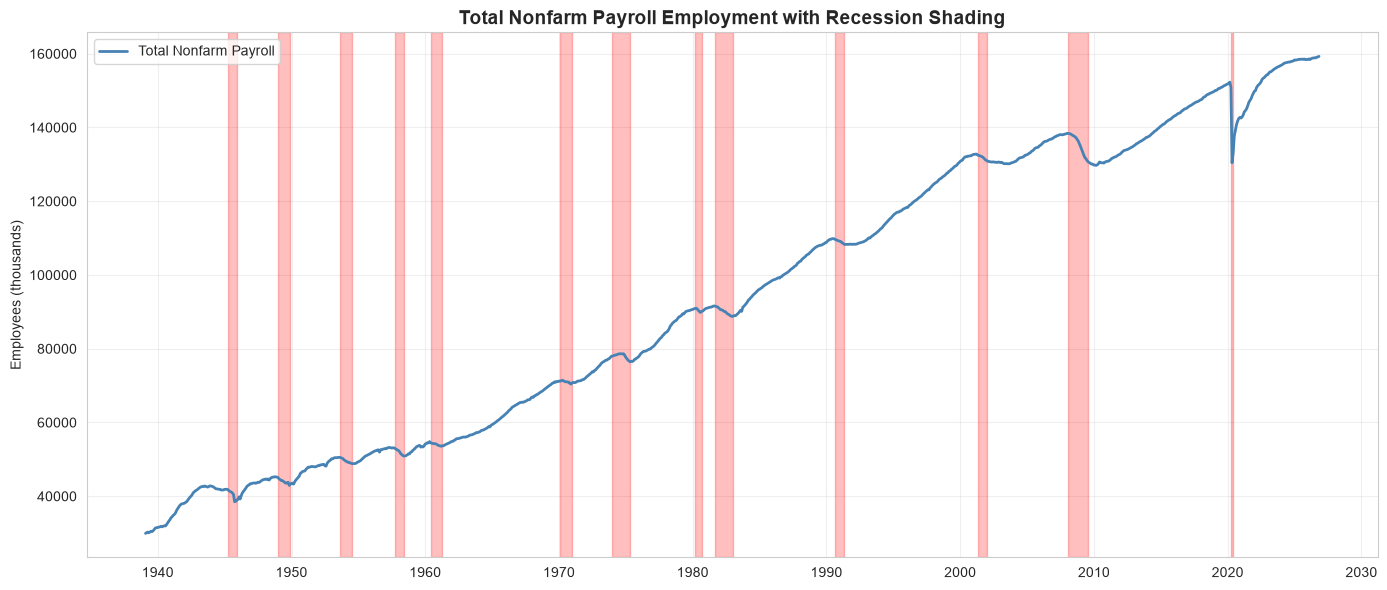

In [4]:
fig, ax = plt.subplots()
ax.plot(df.index, df["total_nonfarm_payroll"], color="steelblue", linewidth=2, label="Total Nonfarm Payroll")
shade_recessions(ax, df)
ax.set_title("Total Nonfarm Payroll Employment with Recession Shading", fontsize=14, fontweight="bold")
ax.set_ylabel("Employees (thousands)")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Chart 2: Hook #1 â€” Crossover moment

White-collar % vs blue-collar % of the core cohort. Dashed line at 50% shows when white-collar overtook blue-collar.


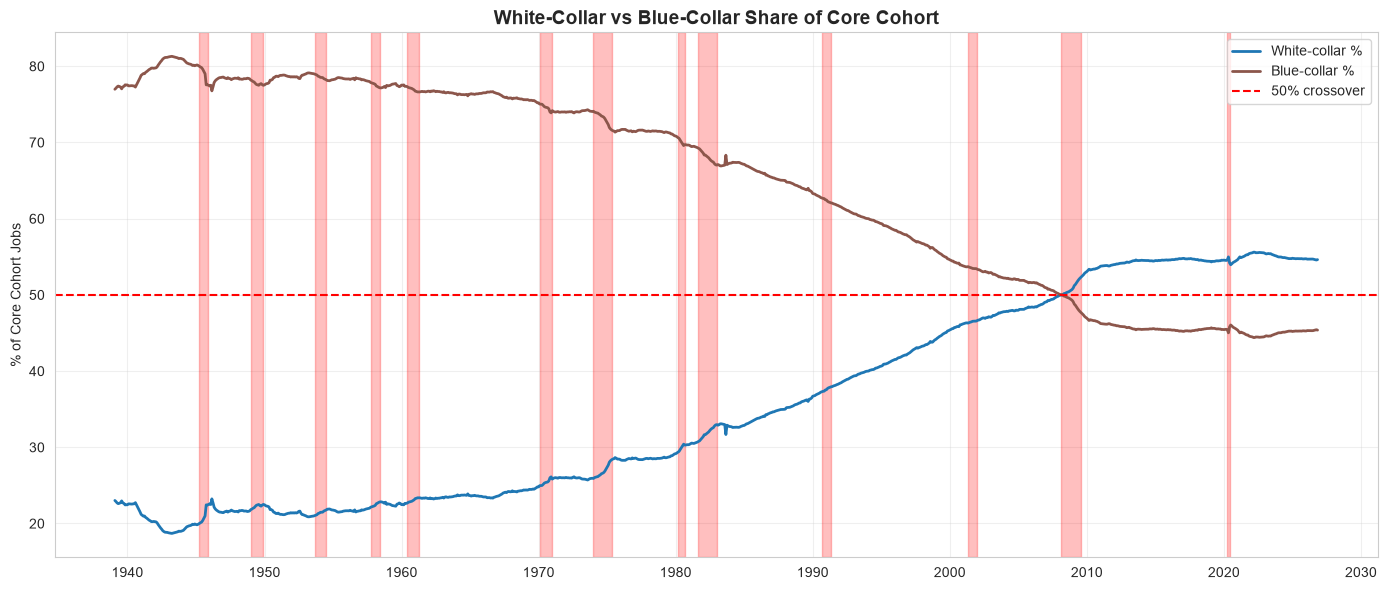

In [5]:
fig, ax = plt.subplots()
ax.plot(df.index, df["white_collar_pct"], color="tab:blue", linewidth=2, label="White-collar %")
ax.plot(df.index, df["blue_collar_pct"], color="tab:brown", linewidth=2, label="Blue-collar %")
ax.axhline(50, color="red", linestyle="--", linewidth=1.5, label="50% crossover")
shade_recessions(ax, df)
ax.set_title("White-Collar vs Blue-Collar Share of Core Cohort", fontsize=14, fontweight="bold")
ax.set_ylabel("% of Core Cohort Jobs")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Chart 3: Hook #2 — First blood (event study)

Average % employment change from t-6 to t+12 months around recession start dates (t=0).
Shows whether blue-collar or white-collar jobs drop first and fastest.


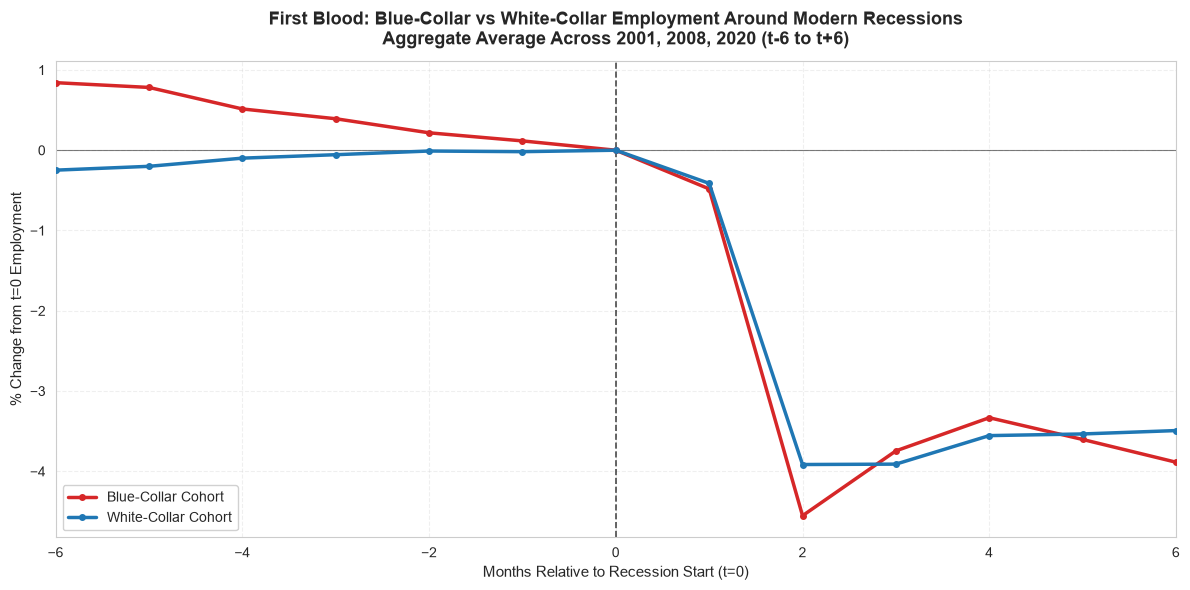

In [6]:


emp_cohorts = [
    ("blue_collar_jobs", "Blue-Collar Cohort", "#d62728"),
    ("white_collar_jobs", "White-Collar Cohort", "#1f77b4"),
]

modern_shocks = [
    ("2001 Dot-Com", pd.Timestamp("2001-03-31")),
    ("2008 GFC",     pd.Timestamp("2007-12-31")),
    ("2020 COVID",   pd.Timestamp("2020-02-29")),
]

months_range = list(range(-6, 7))  # t-6 to t+6

# Aggregate across 3 recessions
agg_trajectories = {}
for col, label, color in emp_cohorts:
    agg_trajectories[col] = []
    for m in months_range:
        changes = []
        for shock_name, shock_start in modern_shocks:
            if shock_start not in df.index:
                continue
            tm = shock_start + pd.offsets.MonthEnd(m)
            if tm in df.index:
                base = df.loc[shock_start, col]
                val = df.loc[tm, col]
                if base > 0:
                    changes.append((val / base - 1) * 100)
        if changes:
            agg_trajectories[col].append((m, np.mean(changes)))
        else:
            agg_trajectories[col].append((m, np.nan))

fig, ax = plt.subplots(figsize=(12, 6))

for col, label, color in emp_cohorts:
    data = agg_trajectories[col]
    months = [d[0] for d in data]
    vals = [d[1] for d in data]
    valid = [(m, v) for m, v in zip(months, vals) if not np.isnan(v)]
    if valid:
        mv, vv = zip(*valid)
        ax.plot(mv, vv, color=color, linewidth=2.5, marker="o", markersize=4,
                label=label, zorder=3)

ax.axvline(0, color="black", linestyle="--", linewidth=1.2, alpha=0.7)
ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)
ax.set_title("First Blood: Blue-Collar vs White-Collar Employment Around Modern Recessions\nAggregate Average Across 2001, 2008, 2020 (t-6 to t+6)",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Months Relative to Recession Start (t=0)", fontsize=11)
ax.set_ylabel("% Change from t=0 Employment", fontsize=11)
ax.grid(True, alpha=0.3, linestyle="--")
ax.legend(loc="lower left", fontsize=10, frameon=True, framealpha=0.9)
ax.set_xlim(-6, 6)
ax.set_xticks(range(-6, 7, 2))

plt.tight_layout()
plt.show()


### Chart 4: Hook #3 — Vulnerability shift (era-by-era drawdown)

Compares average employment drawdown during recessions across eras.
Eras are labeled dynamically based on your actual data start date.


Total distinct recession episodes found: 13
| Era                   |   Blue-Collar Max Drawdown % |   White-Collar Max Drawdown % |   N Recession Episodes |
|:----------------------|-----------------------------:|------------------------------:|-----------------------:|
| Modern (1990–Present) |                     -9.025   |                      -5.85    |                      4 |
| Past (1939–1989)      |                     -8.61111 |                      -2.15556 |                      9 |



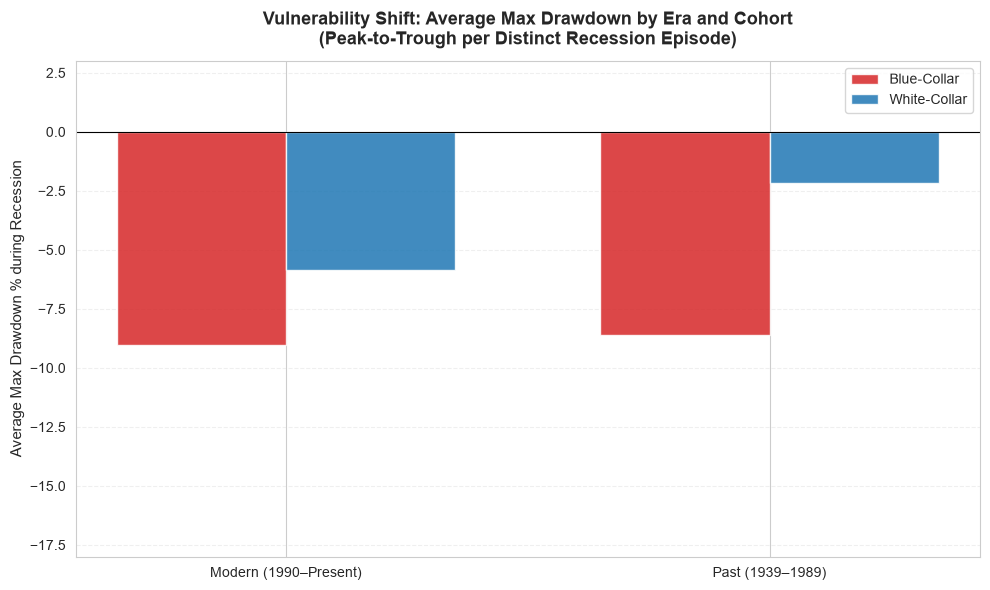

In [8]:


# Find distinct recession episodes (contiguous blocks of indicator == 1)
recession_episodes = []
in_recession = False
episode_start = None

for date, row in df.iterrows():
    if row["recession_indicator"] == 1 and not in_recession:
        # Recession starts
        in_recession = True
        episode_start = date
    elif row["recession_indicator"] == 0 and in_recession:
        # Recession ends
        in_recession = False
        recession_episodes.append((episode_start, date - pd.Timedelta(days=1)))

# If data ends while still in recession, close it at last date
if in_recession:
    recession_episodes.append((episode_start, df.index[-1]))

print(f"Total distinct recession episodes found: {len(recession_episodes)}")

# Calculate max drawdown per episode
era_drawdowns = []

for rec_start, rec_end in recession_episodes:
    era = "Past (1939–1989)" if rec_start.year <= 1989 else "Modern (1990–Present)"
    
    # Base = last observation before recession starts
    base_idx = df.index[df.index <= rec_start][-1]
    base_blue = df.loc[base_idx, "blue_collar_jobs"]
    base_white = df.loc[base_idx, "white_collar_jobs"]
    
    # Recession window
    rec_window = df.loc[rec_start:rec_end]
    
    if len(rec_window) == 0:
        continue
    
    trough_blue = rec_window["blue_collar_jobs"].min()
    trough_white = rec_window["white_collar_jobs"].min()
    
    drawdown_blue = (trough_blue / base_blue - 1) * 100
    drawdown_white = (trough_white / base_white - 1) * 100
    
    era_drawdowns.append({
        "Era": era,
        "Recession Start": rec_start.date(),
        "Blue-Collar Max Drawdown %": round(drawdown_blue, 1),
        "White-Collar Max Drawdown %": round(drawdown_white, 1),
    })

if not era_drawdowns:
    print("⚠️ No recession episodes found — check recession_indicator column")
else:
    drawdown_df = pd.DataFrame(era_drawdowns)
    
    # Aggregate by era
    era_summary = drawdown_df.groupby("Era").agg({
        "Blue-Collar Max Drawdown %": "mean",
        "White-Collar Max Drawdown %": "mean",
        "Recession Start": "count",
    }).rename(columns={"Recession Start": "N Recession Episodes"}).reset_index()
    
    print(era_summary.to_markdown(index=False))
    print()
    
    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))
    
    x = np.arange(len(era_summary))
    width = 0.35
    
    blue_drawdowns = era_summary["Blue-Collar Max Drawdown %"].values
    white_drawdowns = era_summary["White-Collar Max Drawdown %"].values
    
    ax.bar(x - width/2, blue_drawdowns, width, label="Blue-Collar", color="#d62728", alpha=0.85)
    ax.bar(x + width/2, white_drawdowns, width, label="White-Collar", color="#1f77b4", alpha=0.85)
    
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(era_summary["Era"], rotation=0)
    ax.set_ylabel("Average Max Drawdown % during Recession", fontsize=11)
    ax.set_title("Vulnerability Shift: Average Max Drawdown by Era and Cohort\n(Peak-to-Trough per Distinct Recession Episode)",
                 fontsize=13, fontweight="bold", pad=12)
    ax.legend()
    ax.grid(True, alpha=0.3, axis="y", linestyle="--")
    ax.set_ylim(-18, 3)
    
    plt.tight_layout()
    plt.show()


### Chart 5: Hook #4 — Sub-sector bifurcation

Individual sector drawdowns across major recessions (2001, 2008, 2020).
Shows which sectors got hit hardest in each downturn.


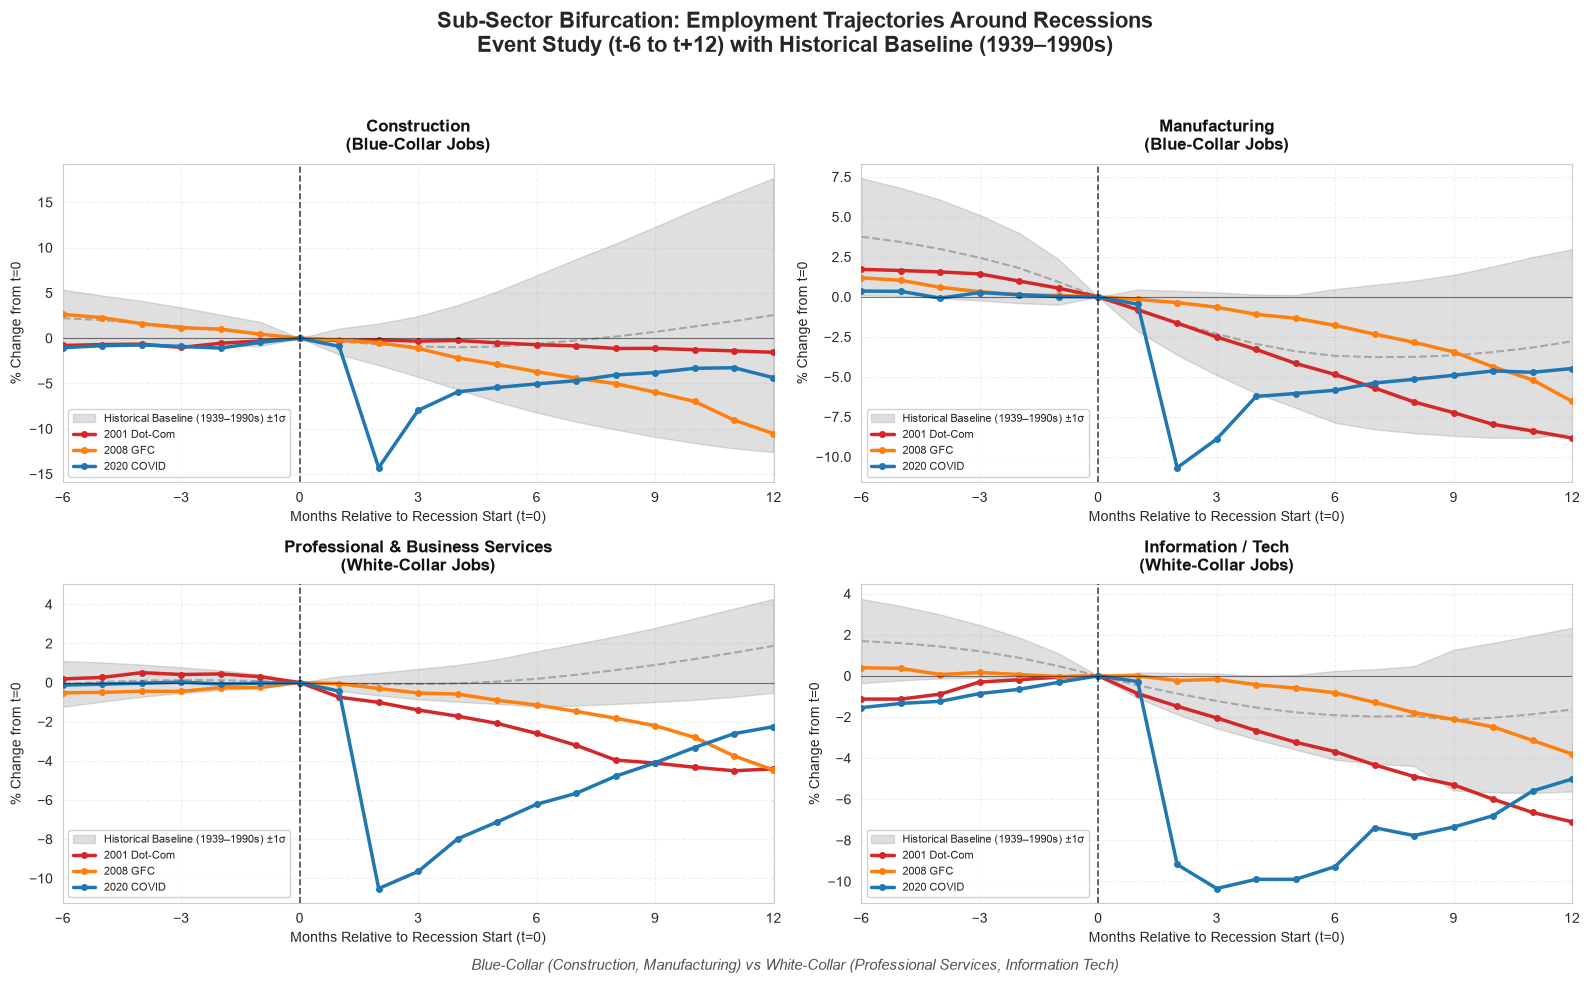

In [9]:


# Sector info: (column, label, line_color, economic_class)
sector_info = [
    ("construction_employment", "Construction", "#d62728", "Blue-Collar"),
    ("manufacturing_employment", "Manufacturing", "#ff7f0e", "Blue-Collar"),
    ("professional_business_services", "Professional & Business Services", "#1f77b4", "White-Collar"),
    ("information_sector", "Information / Tech", "#2ca02c", "White-Collar"),
]

# Modern shocks — month-end dates matching master_table.csv index exactly
modern_shocks = [
    ("2001 Dot-Com", pd.Timestamp("2001-03-31"), "#d62728"),
    ("2008 GFC",     pd.Timestamp("2007-12-31"), "#ff7f0e"),
    ("2020 COVID",   pd.Timestamp("2020-02-29"), "#1f77b4"),
]

months_range = list(range(-6, 13))  # t-6 to t+12

# Historical baseline: pre-1990s recessions (1939–1999)
pre_1990_rec_starts = df[
    (df["recession_indicator"] == 1) &
    (df.index.year >= 1939) &
    (df.index.year <= 1999)
].index

baseline_trajectories = {}

for col, label, _, _ in sector_info:
    baseline_trajectories[col] = []
    for m in months_range:
        changes = []
        for start in pre_1990_rec_starts:
            tm = start + pd.offsets.MonthEnd(m)
            if tm in df.index:
                base_val = df.loc[start, col]
                tm_val = df.loc[tm, col]
                if base_val > 0:
                    changes.append((tm_val / base_val - 1) * 100)
        if changes:
            baseline_trajectories[col].append((m, np.mean(changes), np.std(changes)))
        else:
            baseline_trajectories[col].append((m, np.nan, np.nan))

# Create 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=False)
axes = axes.flatten()

for idx, (col, label, color, econ_class) in enumerate(sector_info):
    ax = axes[idx]

    # Historical baseline band (pre-1990s)
    baseline_data = baseline_trajectories[col]
    baseline_months = [b[0] for b in baseline_data]
    baseline_means = [b[1] for b in baseline_data]
    baseline_stds = [b[2] for b in baseline_data]

    valid_mask = ~np.isnan(baseline_means)
    bm = [baseline_months[i] for i in range(len(baseline_months)) if valid_mask[i]]
    bmeans = [baseline_means[i] for i in range(len(baseline_means)) if valid_mask[i]]
    bstds = [baseline_stds[i] for i in range(len(baseline_stds)) if valid_mask[i]]

    if bmeans:
        ax.fill_between(
            bm,
            np.array(bmeans) - np.array(bstds),
            np.array(bmeans) + np.array(bstds),
            color="grey",
            alpha=0.25,
            label="Historical Baseline (1939–1990s) ±1σ",
            zorder=1,
        )
        ax.plot(
            bm,
            bmeans,
            color="grey",
            alpha=0.6,
            linewidth=1.5,
            linestyle="--",
            zorder=2,
        )

    # Modern shock event studies (raw monthly % change, no smoothing)
    for shock_name, shock_start, shock_color in modern_shocks:
        if shock_start not in df.index:
            continue

        changes = []
        change_months = []
        for m in months_range:
            tm = shock_start + pd.offsets.MonthEnd(m)  # ✅ MonthEnd alignment
            if tm in df.index:
                base_val = df.loc[shock_start, col]
                tm_val = df.loc[tm, col]
                if base_val > 0:
                    changes.append((tm_val / base_val - 1) * 100)
                    change_months.append(m)

        if changes:
            ax.plot(
                change_months,
                changes,
                color=shock_color,
                linewidth=2.5,
                marker="o",
                markersize=4,
                label=shock_name,
                zorder=3,
            )

    # Formatting
    ax.axvline(0, color="black", linestyle="--", linewidth=1.2, alpha=0.7, zorder=4)
    ax.axhline(0, color="black", linewidth=0.8, alpha=0.5, zorder=4)
    ax.set_title(
        f"{label}\n({econ_class} Jobs)",
        fontsize=12,
        fontweight="bold",
        pad=10,
        color="#111111",
    )
    ax.set_xlabel("Months Relative to Recession Start (t=0)", fontsize=10)
    ax.set_ylabel("% Change from t=0", fontsize=10)
    ax.grid(True, alpha=0.3, linestyle="--", zorder=0)
    ax.legend(loc="lower left", fontsize=8, frameon=True, framealpha=0.9)
    ax.set_xlim(-6, 12)
    ax.set_xticks(range(-6, 13, 3))

fig.suptitle(
    "Sub-Sector Bifurcation: Employment Trajectories Around Recessions\nEvent Study (t-6 to t+12) with Historical Baseline (1939–1990s)",
    fontsize=16,
    fontweight="bold",
    y=0.98,
)
fig.text(
    0.5,
    0.02,
    "Blue-Collar (Construction, Manufacturing) vs White-Collar (Professional Services, Information Tech)",
    ha="center",
    fontsize=11,
    style="italic",
    color="#555555",
)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()
